<a href="https://colab.research.google.com/github/gioftaka/Modelagem-Termica-e-Processamento-de-Sinal-de-Termopar-MI/blob/main/Trab_Final_Mat_Comp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução

Na automação industrial, os termopares são amplamente utilizados para a medição de temperatura. Esses sensores são constituídos por dois fios de materiais diferentes, que permanecem eletricamente isolados entre si ao longo de seu comprimento. Na extremidade de medição, os fios são unidos por soldagem, formando a chamada junção quente, que pode ser aterrada ou não aterrada. No modelo de junção não aterrada, a união entre os condutores não entra em contato com a bainha metálica, permanecendo eletricamente isolada dela.

Em termopares industriais com isolação mineral, os condutores são envolvidos por um material isolante, geralmente óxido de magnésio (MgO), que preenche o espaço interno da bainha metálica. A bainha atua como uma barreira de proteção entre os componentes internos do sensor e o fluido do processo, sendo frequentemente fabricada em aço inoxidável, cuja composição deve ser selecionada conforme as condições químicas e térmicas de operação. O MgO, além de proporcionar isolamento elétrico entre os condutores e a bainha, permite a transferência de calor até a região de medição.

Esse conjunto construtivo apresenta resistência à transferência de calor e capacidade de armazenamento de energia térmica, contribuindo para a inércia térmica do sensor. Dessa forma, quando o termopar é submetido a uma alteração na temperatura do processo, o calor precisa atravessar diferentes regiões e materiais até atingir a junção quente, fazendo com que a resposta do sensor apresente um atraso em relação à temperatura do fluido.

O objetivo deste trabalho é modelar a dinâmica de propagação do calor através do encapsulamento de um termopar industrial utilizando Equações Diferenciais Parciais (EDPs), considerando separadamente as propriedades térmicas da bainha de aço inoxidável e da isolação de óxido de magnésio. Para isso, utiliza-se uma aproximação unidimensional e o método das diferenças finitas para obter a distribuição de temperatura ao longo do tempo. Posteriormente, pretende-se simular o processamento digital do sinal elétrico gerado pelo sensor, buscando atenuar interferências eletromagnéticas características de ambientes industriais.

# Modelagem Matemática da Transferência de Calor

A transferência de calor através do encapsulamento do termopar ocorre predominantemente por condução térmica entre as regiões que compõem sua estrutura. Como a bainha metálica e o material isolante possuem propriedades termofísicas distintas, a modelagem considera duas regiões, cada uma descrita por uma Equação do Calor unidimensional.

Para simplificar a representação matemática, considera-se a propagação de calor ao longo da espessura do encapsulamento, desde a superfície externa da bainha até a região central do domínio, utilizada como aproximação da região de medição. Essa abordagem permite representar separadamente a condução térmica no aço inoxidável e no MgO, sem modelar individualmente os fios, a geometria cilíndrica completa e a junção quente real.

## Equações Diferenciais Parciais

**1. Região da bainha metálica (aço inoxidável)**

Na região correspondente à bainha metálica, a propagação de calor é descrita por:


$\frac{\partial T_1}{\partial t} = \alpha_1\frac{\partial^2 T_1}{\partial x^2}$

Em que:


$\alpha_1=\frac{k_1}{\rho_1c_{p1}}$

**2. Região da isolação mineral (óxido de magnésio - MgO)**

Na região interna preenchida pelo material isolante, a transferência de calor é representada por:


$\frac{\partial T_2}{\partial t} = \alpha_2\frac{\partial^2 T_2}{\partial x^2} $

Em que:

$
\alpha_2=\frac{k_2}{\rho_2c_{p2}}
$

As duas equações são acopladas pela interface entre os materiais, permitindo representar a continuidade da temperatura e do fluxo de calor durante a transferência de energia térmica da bainha para a isolação mineral.

## Definição dos termos e parâmetros físicos

- $T_1(x,t)$: distribuição de temperatura na região da bainha de aço inoxidável, em °C.
- $T_2(x,t)$: distribuição de temperatura na região da isolação de MgO, em °C.
- $t$: tempo decorrido desde a exposição do sensor ao processo térmico, em segundos.
- $x$: posição espacial ao longo do domínio unidimensional, em metros.
- $\alpha_1$: difusividade térmica do aço inoxidável, em m²/s.
- $\alpha_2$: difusividade térmica do MgO, em m²/s.
- $k_1$ e $k_2$: condutividades térmicas do aço inoxidável e do MgO, respectivamente, em W/(m·K).
- $\rho_1$ e $\rho_2$: massas específicas dos respectivos materiais, em kg/m³.
- $c_{p1}$ e $c_{p2}$: calores específicos dos respectivos materiais, em J/(kg·K).

Para a definição do domínio espacial, considera-se:

- $x=0$: superfície externa da bainha metálica.
- $x=L_1$: interface entre a bainha de aço inoxidável e a isolação de MgO.
- $x=L$: extremidade interna do domínio, utilizada como aproximação da região de medição.

Assim, $L_1$ representa a espessura radial adotada para a região metálica, enquanto $L-L_1$ representa a extensão da região preenchida pelo MgO no modelo simplificado.

Para a geometria de referência adotada na simulação, considera-se um diâmetro externo de 3,0 mm, uma espessura de bainha de 0,30 mm e uma extensão interna aproximada de 1,20 mm. Dessa forma:

$
L_1=0,00030\ m
$

$
L-L_1=0,00120\ m
$

$
L=0,00150\ m
$

Essas dimensões representam uma aproximação para a construção de um termopar mineral-isolado.

## Hipóteses

Para a formulação do modelo matemático, são adotadas as seguintes hipóteses físicas:

- A propagação de calor ocorre de forma unidimensional ao longo do domínio, representando uma aproximação simplificada da geometria cilíndrica do sensor.
- A bainha metálica é constituída de aço inoxidável 316L, enquanto a região interna de isolação é preenchida por óxido de magnésio (MgO).
- As propriedades termofísicas de cada material, como condutividade térmica ($k$), massa específica ($\rho$) e calor específico ($c_p$), são homogêneas, isotrópicas e constantes durante a simulação.
- Não há geração interna de energia térmica nos materiais.
- Existe contato térmico ideal entre a bainha metálica e a isolação mineral, não sendo considerada resistência térmica de contato na interface.
- A bainha permanece íntegra durante o processo, sem considerar degradação ou perfuração por corrosão.
- O material isolante permanece seco, mantendo suas propriedades térmicas e elétricas.
- A junção quente é considerada eletricamente isolada da bainha metálica, conforme a configuração de um termopar de junção não aterrada.
- A extremidade interna do domínio é considerada termicamente isolada, como uma simplificação matemática para representar o limite interno do modelo.

## Condições Iniciais e de Contorno

Para representar a exposição do termopar a um processo industrial, define-se um Problema de Valor Inicial e de Contorno (PVC), considerando as duas regiões de materiais e suas respectivas interfaces.

**Condição Inicial (CI):**

Inicialmente, o sensor encontra-se em equilíbrio térmico com o ambiente, à temperatura de 25 °C, antes de ser inserido no processo. Portanto, as duas regiões apresentam a mesma temperatura inicial:

$
T_1(x,0)=25,\quad 0\leq x\leq L_1
$

$
T_2(x,0)=25,\quad L_1\leq x\leq L
$

**Condição de Contorno 1 — Temperatura imposta na superfície externa (Dirichlet):**

No instante $t>0$, considera-se que a superfície externa do sensor é submetida instantaneamente à temperatura de 150 °C, representando uma aproximação da exposição ao processo térmico. Dessa forma:

$
T_1(0,t)=150,\quad t>0
$

Essa condição estabelece uma temperatura constante na superfície externa da bainha durante toda a simulação.

**Condição de Contorno 2 — Continuidade térmica na interface entre os materiais:**

Na interface entre o aço inoxidável e o MgO, localizada em $x=L_1$, considera-se que não existe resistência térmica de contato. Dessa forma, a temperatura e o fluxo de calor devem ser contínuos:

$
T_1(L_1,t)=T_2(L_1,t)
$

$ k_1\frac{\partial T_1}{\partial x}(L_1,t) = k_2\frac{\partial T_2}{\partial x}(L_1,t) $

Essas condições garantem que o calor transferido pela bainha metálica seja conduzido para a região interna de isolação mineral.

**Condição de Contorno 3 — Fluxo nulo na extremidade interna (Neumann):**

Na extremidade interna do domínio, localizada em $x=L$, considera-se que não há fluxo de calor atravessando o limite. Matematicamente, essa condição é representada por:

$
\frac{\partial T_2}{\partial x}(L,t)=0
$

Essa condição representa uma extremidade termicamente isolada no modelo unidimensional. Trata-se de uma hipótese simplificadora, não de uma reprodução exata da junção quente não aterrada, que se encontra na extremidade longitudinal dos condutores.

Dessa maneira, o modelo matemático considera a propagação de calor a partir de uma superfície externa submetida a uma temperatura constante de 150 °C, sua condução pela bainha de aço inoxidável, a transferência de energia através da interface com o MgO e a propagação subsequente em direção à extremidade interna do domínio.

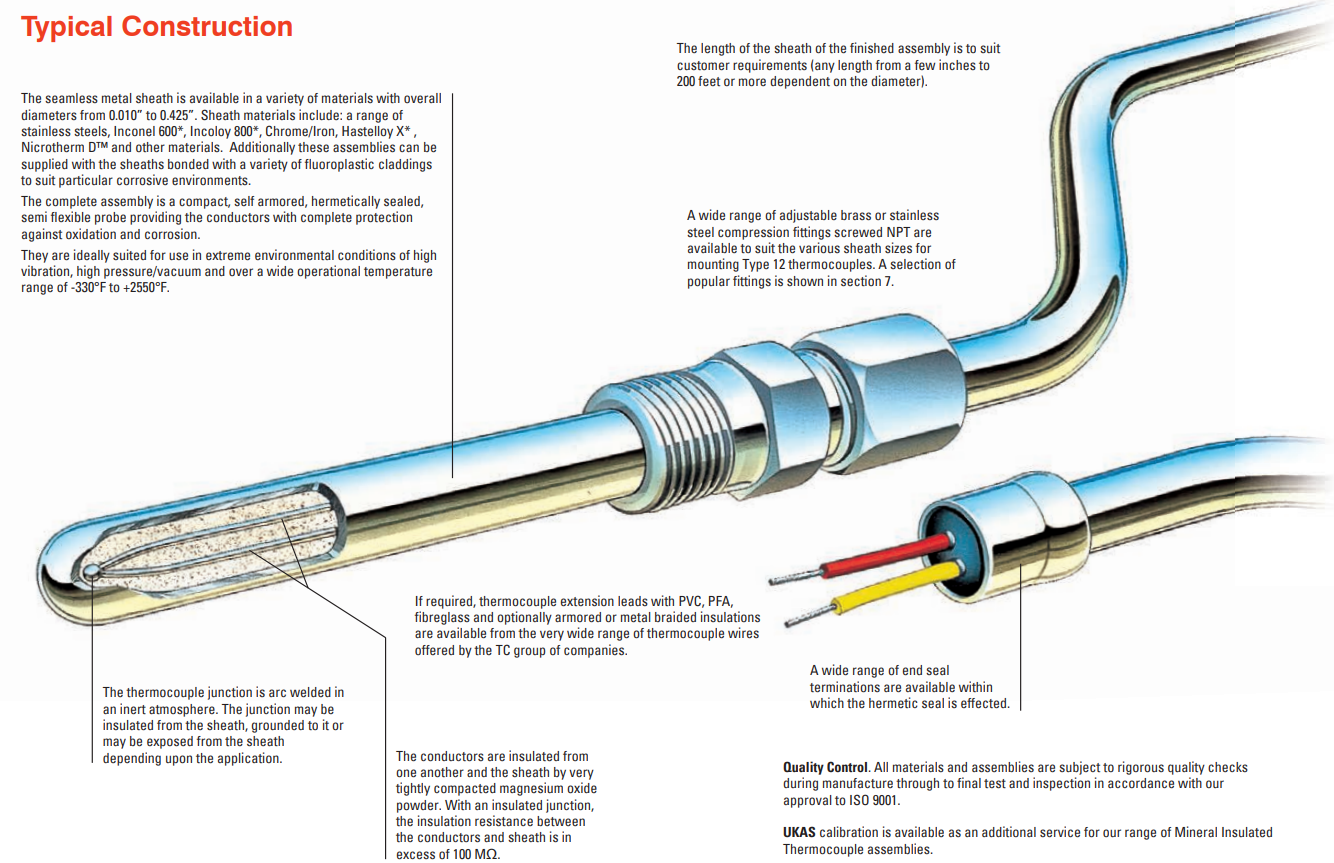

Passo espacial (dx): 0.00003000 m
Passo temporal (dt): 2.47200000e-05 s
Difusividade do aço: 3.797e-06 m²/s
Difusividade do MgO: 1.146e-06 m²/s


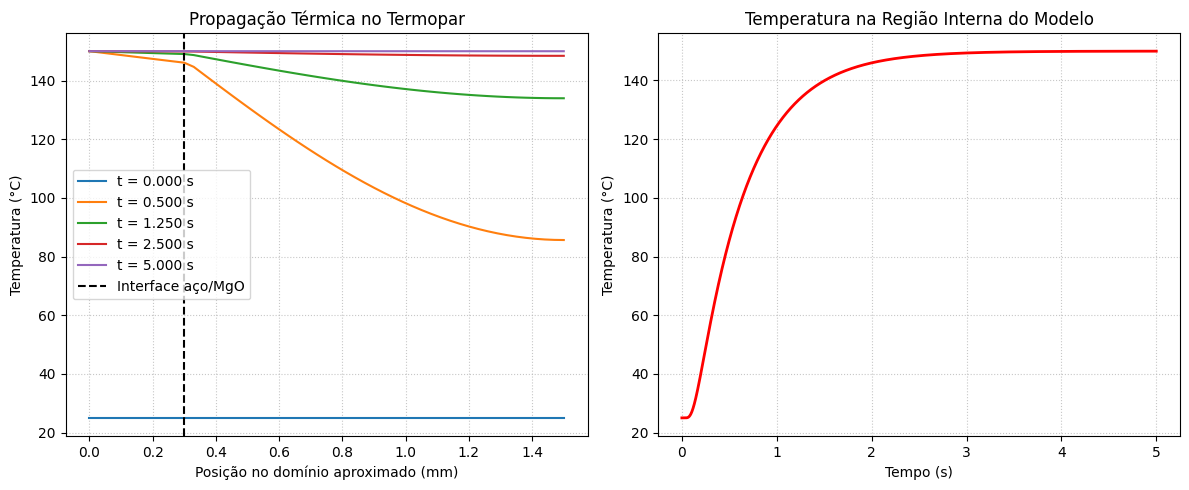

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros físicos e da malha

# Geometria de referência de um termopar MI de 3,0 mm
L_aco = 0.00030  # Espessura radial aproximada da bainha (m)
L_mgo = 0.00120  # Extensão aproximada da região de MgO (m)
L = L_aco + L_mgo

T_max = 5.0

# Propriedades térmicas do aço inoxidável 316L
k_aco = 15.0
rho_aco = 7900.0
cp_aco = 500.0

# Propriedades térmicas aproximadas do MgO compactado
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 1030.0

# Cálculo das difusividades térmicas
alpha_aco = k_aco / (rho_aco * cp_aco)
alpha_mgo = k_mgo / (rho_mgo * cp_mgo)

# Malha espacial
Nx = 51
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

# Identificação do material em cada posição
k = np.where(x <= L_aco, k_aco, k_mgo)
rho = np.where(x <= L_aco, rho_aco, rho_mgo)
cp = np.where(x <= L_aco, cp_aco, cp_mgo)

alpha = k / (rho * cp)

# Condutividade térmica nas interfaces entre os pontos
k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

# Critério de estabilidade para o método explícito
dt = 0.2 * np.min(rho * cp) * dx**2 / np.max(k)
Nt = int(T_max / dt) + 1

print(f"Passo espacial (dx): {dx:.8f} m")
print(f"Passo temporal (dt): {dt:.8e} s")
print(f"Difusividade do aço: {alpha_aco:.3e} m²/s")
print(f"Difusividade do MgO: {alpha_mgo:.3e} m²/s")

# 2. Inicialização das matrizes

# O sensor começa à temperatura ambiente
u = np.ones(Nx) * 25.0

u_novo = np.copy(u)

# Histórico da temperatura na região interna do modelo
historico_nucleo = np.zeros(Nt)
historico_nucleo[0] = u[-1]

# Armazenamento das curvas para os gráficos
curvas_tempo = [(0, np.copy(u))]
tempos_plot = [Nt // 10, Nt // 4, Nt // 2, Nt - 1]

# 3. Loop de diferenças finitas (FTCS)

for n in range(1, Nt):

    for i in range(1, Nx - 1):

        fluxo_direita = k_face[i] * (u[i+1] - u[i])
        fluxo_esquerda = k_face[i-1] * (u[i] - u[i-1])

        u_novo[i] = u[i] + (
            dt / (rho[i] * cp[i] * dx**2)
        ) * (fluxo_direita - fluxo_esquerda)

    # Condição de contorno: superfície a 150 °C
    u_novo[0] = 150.0

    # Condição de fluxo nulo na extremidade interna
    u_novo[-1] = u[-1] + (
        2 * dt * k_face[-1] *
        (u[-2] - u[-1]) /
        (rho[-1] * cp[-1] * dx**2)
    )

    # Atualização da temperatura
    u = np.copy(u_novo)

    # Armazenamento da temperatura na região interna
    historico_nucleo[n] = u[-1]

    if n in tempos_plot:
        curvas_tempo.append((n * dt, np.copy(u)))

# 4. Visualização 1: propagação espacial

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

for t_val, curva in curvas_tempo:
    plt.plot(x * 1000, curva, label=f't = {t_val:.3f} s')

plt.axvline(
    x=L_aco * 1000,
    color='black',
    linestyle='--',
    label='Interface aço/MgO'
)

plt.title('Propagação Térmica no Termopar')
plt.xlabel('Posição no domínio aproximado (mm)')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

# 5. Visualização 2: resposta dinâmica

plt.subplot(1, 2, 2)

vetor_tempo = np.arange(Nt) * dt

plt.plot(
    vetor_tempo,
    historico_nucleo,
    color='red',
    linewidth=2
)

plt.title('Temperatura na Região Interna do Modelo')
plt.xlabel('Tempo (s)')
plt.ylabel('Temperatura (°C)')
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()


### Solução Analítica e Série de Fourier

A solução analítica da equação do calor pode ser construída pela soma de uma parcela estacionária $v(x)$ e uma parcela transiente $w(x,t)$.

Para o modelo considerado, a superfície externa do termopar é submetida a uma temperatura constante de $150\,^\circ\text{C}$, enquanto a extremidade interna apresenta condição de fluxo térmico nulo. Como não há geração interna de calor, a distribuição de temperatura no estado estacionário é uniforme:

$
v(x)=150
$

A condição inicial estabelece que todo o domínio se encontra inicialmente à temperatura ambiente:

$
f(x)=25
$

Dessa forma, a diferença entre a condição inicial e o estado estacionário é:

$
f(x)-v(x)=25-150=-125
$

Para um domínio homogêneo, considerando as condições de contorno de temperatura fixa em uma extremidade e fluxo nulo na outra, a solução transiente pode ser representada por uma série de Fourier:

$
w(x,t)=
-\sum_{n=0}^{\infty}
\frac{500}{(2n+1)\pi}
\sin\left(\frac{(n+\frac12)\pi x}{L}\right)
e^{-\alpha\left(\frac{(n+\frac12)\pi}{L}\right)^2t}
$

Entretanto, o modelo numérico desenvolvido neste trabalho considera duas regiões com propriedades térmicas distintas: a bainha de aço inoxidável 316L e o preenchimento de MgO compactado. Portanto, a expressão apresentada para o domínio homogêneo não corresponde à solução analítica exata do sistema estudado, pois esta exigiria considerar as diferentes difusividades térmicas e as condições de continuidade de temperatura e fluxo de calor na interface entre os materiais.

Assim, a solução numérica pelo método das diferenças finitas (FTCS) é utilizada para representar a propagação térmica no domínio composto pelos dois materiais.

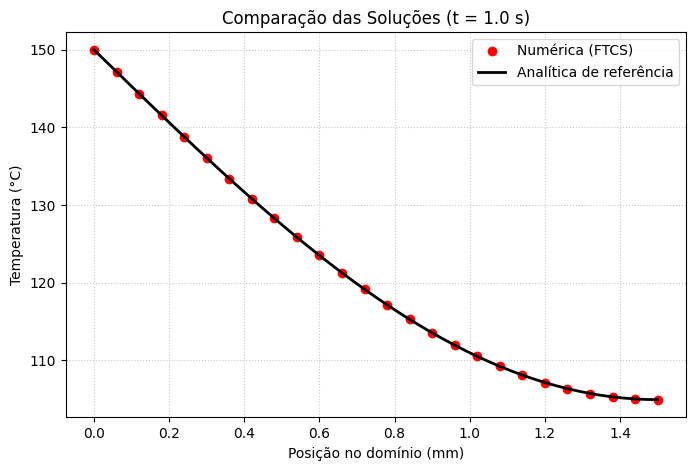

In [22]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros físicos
L = 0.0015
alpha = 1.15e-6
T_max = 1.0

# 2. Parâmetros numéricos
Nx = 51
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

dt = 0.2 * dx**2 / alpha
Nt = int(T_max / dt) + 1
F = alpha * dt / dx**2

# 3. Solução numérica FTCS
u_num = np.ones(Nx) * 25.0
u_novo = np.copy(u_num)

for n in range(1, Nt):

    u_novo[1:-1] = u_num[1:-1] + F * (
        u_num[2:] - 2*u_num[1:-1] + u_num[:-2]
    )

    # Temperatura fixa na superfície
    u_novo[0] = 150.0

    # Fluxo nulo na extremidade interna
    u_novo[-1] = u_num[-1] + 2*F*(u_num[-2] - u_num[-1])

    u_num = np.copy(u_novo)

# 4. Solução analítica de referência
u_ana = np.ones(Nx) * 150.0

num_termos = 100

for n in range(num_termos):

    Cn = -500.0 / ((2*n + 1) * np.pi)

    exponencial = np.exp(
        -alpha * (((n + 0.5)*np.pi/L)**2) * T_max
    )

    u_ana += Cn * np.sin(
        (n + 0.5)*np.pi*x/L
    ) * exponencial

# 5. Gráfico comparativo
plt.figure(figsize=(8, 5))

plt.plot(
    x*1000, u_num, 'ro',
    label='Numérica (FTCS)', markevery=2
)

plt.plot(
    x*1000, u_ana, 'k-',
    linewidth=2, label='Analítica de referência'
)

plt.title(f'Comparação das Soluções (t = {T_max} s)')
plt.xlabel('Posição no domínio (mm)')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.show()


### Análise da Influência das Propriedades Térmicas na Resposta do Sensor

Após a análise da propagação térmica no domínio e a comparação entre as soluções numérica e analítica de referência, o estudo avança para a investigação da influência das propriedades térmicas dos materiais na resposta do termopar.

A difusividade térmica ($\alpha$) está relacionada à velocidade com que as variações de temperatura se propagam em um material. Dessa forma, materiais com diferentes valores de difusividade apresentam comportamentos distintos durante o aquecimento, podendo atingir determinadas temperaturas em intervalos de tempo diferentes.

Nesta etapa, busca-se analisar como as propriedades térmicas dos materiais que compõem o sensor influenciam sua resposta ao ser submetido a uma variação de temperatura no ambiente de medição.

É importante considerar que, no termopar estudado, a bainha de aço inoxidável 316L e o preenchimento de MgO compactado possuem propriedades térmicas distintas. Portanto, a resposta do conjunto depende da interação entre esses materiais, e não apenas da difusividade térmica da bainha isoladamente.

Para investigar esse comportamento, será desenvolvida uma simulação numérica baseada no método FTCS, acompanhando a evolução da temperatura na região interna do domínio ao longo do tempo.

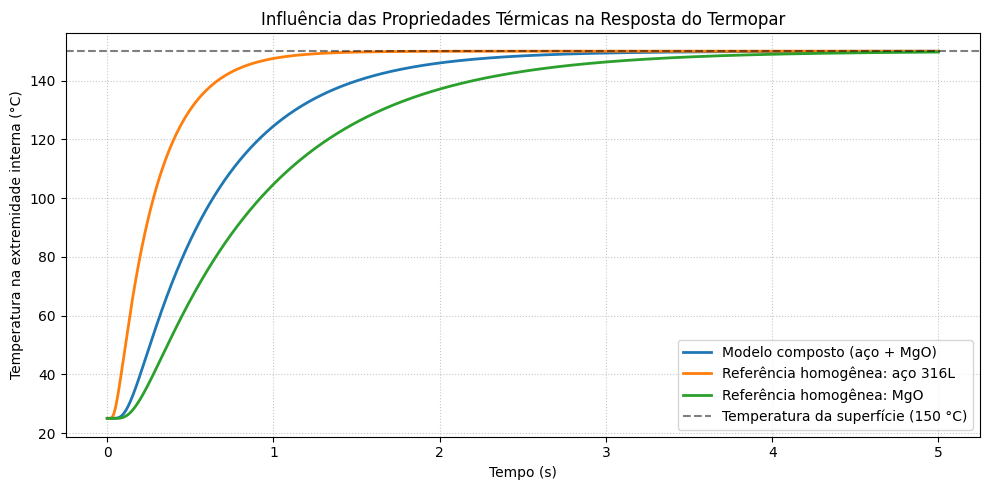

In [23]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Geometria do termopar
L_aco = 0.00030
L_mgo = 0.00120
L = L_aco + L_mgo

T_max = 5.0

# 2. Propriedades térmicas dos materiais

# Aço inoxidável 316L
k_aco = 15.0
rho_aco = 7900.0
cp_aco = 500.0

# MgO compactado
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 1030.0

# 3. Malha espacial
Nx = 51
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

# Identificação dos materiais no modelo composto
k_comp = np.where(x <= L_aco, k_aco, k_mgo)
rho_comp = np.where(x <= L_aco, rho_aco, rho_mgo)
cp_comp = np.where(x <= L_aco, cp_aco, cp_mgo)

# 4. Critério de estabilidade comum às simulações
dt = 0.2 * min(rho_aco*cp_aco, rho_mgo*cp_mgo) * dx**2 / max(k_aco, k_mgo)

Nt = int(T_max / dt) + 1
vetor_tempo = np.arange(Nt) * dt

# 5. Função de simulação pelo método FTCS
def simular_termopar(k, rho, cp):

    # Condição inicial: todo o domínio a 25 °C
    u = np.ones(Nx) * 25.0
    u_novo = np.copy(u)

    # Condutividade térmica nas interfaces
    k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

    # Histórico da temperatura na extremidade interna
    historico_nucleo = np.zeros(Nt)
    historico_nucleo[0] = u[-1]

    for n in range(1, Nt):

        # Cálculo dos fluxos nos pontos internos
        fluxo_direita = k_face[1:] * (u[2:] - u[1:-1])
        fluxo_esquerda = k_face[:-1] * (u[1:-1] - u[:-2])

        # Atualização das temperaturas internas
        u_novo[1:-1] = u[1:-1] + (
            dt / (rho[1:-1] * cp[1:-1] * dx**2)
        ) * (fluxo_direita - fluxo_esquerda)

        # Superfície externa a 150 °C
        u_novo[0] = 150.0

        # Fluxo nulo na extremidade interna
        u_novo[-1] = u[-1] + (
            2 * dt * k_face[-1] * (u[-2] - u[-1]) /
            (rho[-1] * cp[-1] * dx**2)
        )

        # Atualização
        u = np.copy(u_novo)

        historico_nucleo[n] = u[-1]

    return historico_nucleo


# 6. Simulações das três situações

# Modelo real simplificado: aço + MgO
temp_composto = simular_termopar(
    k_comp, rho_comp, cp_comp
)

# Referência homogênea: somente aço
temp_aco = simular_termopar(
    np.ones(Nx) * k_aco,
    np.ones(Nx) * rho_aco,
    np.ones(Nx) * cp_aco
)

# Referência homogênea: somente MgO
temp_mgo = simular_termopar(
    np.ones(Nx) * k_mgo,
    np.ones(Nx) * rho_mgo,
    np.ones(Nx) * cp_mgo
)

# 7. Visualização comparativa
plt.figure(figsize=(10, 5))

plt.plot(
    vetor_tempo, temp_composto,
    linewidth=2, label='Modelo composto (aço + MgO)'
)

plt.plot(
    vetor_tempo, temp_aco,
    linewidth=2, label='Referência homogênea: aço 316L'
)

plt.plot(
    vetor_tempo, temp_mgo,
    linewidth=2, label='Referência homogênea: MgO'
)

plt.axhline(
    y=150.0, color='black',
    linestyle='--', alpha=0.5,
    label='Temperatura da superfície (150 °C)'
)

plt.title('Influência das Propriedades Térmicas na Resposta do Termopar')
plt.xlabel('Tempo (s)')
plt.ylabel('Temperatura na extremidade interna (°C)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()


### Análise dos Resultados da Resposta Dinâmica

A simulação numérica permite observar a influência das propriedades térmicas dos materiais na propagação do calor e na resposta dinâmica do sensor. A difusividade térmica ($\alpha$) está relacionada à capacidade de um material de transmitir variações de temperatura ao longo de sua estrutura, influenciando a velocidade com que o sistema se aproxima do equilíbrio térmico.

No modelo composto, formado pela bainha de aço inoxidável 316L e pelo preenchimento de MgO compactado, a resposta térmica resulta da interação entre as propriedades dos dois materiais. Dessa forma, o comportamento do conjunto não pode ser determinado considerando apenas a difusividade térmica do aço ou do MgO isoladamente.

As curvas de referência homogêneas permitem observar como seria a propagação do calor caso todo o domínio fosse constituído por apenas um dos materiais. Essas comparações auxiliam na compreensão da influência da condutividade térmica, da densidade e do calor específico sobre a evolução da temperatura na região interna do modelo.

Do ponto de vista da engenharia e da instrumentação, essa análise demonstra a importância da escolha dos materiais na construção de sensores térmicos. A bainha precisa apresentar propriedades mecânicas e químicas adequadas às condições do processo, enquanto o material isolante interno também influencia a transferência de calor até a região de medição.

Portanto, os resultados permitem compreender que o tempo de resposta térmica depende das propriedades dos materiais e da configuração construtiva do sensor, não sendo determinado exclusivamente pela difusividade térmica da bainha.

### Processamento Digital do Sinal e Redução de Ruídos

Após a modelagem da propagação térmica e a análise da resposta dinâmica do sensor, a próxima etapa consiste em investigar a influência de interferências externas sobre o sinal medido pelo termopar.

Em ambientes industriais, os sinais elétricos dos sensores podem sofrer interferências eletromagnéticas, incluindo componentes associadas à frequência da rede elétrica. Essas interferências podem provocar oscilações na leitura e dificultar a identificação da temperatura efetiva do processo.

Para representar esse comportamento, será adicionado ao sinal térmico simulado um ruído periódico de 60 Hz, associado à rede elétrica, e um ruído branco, que representa perturbações aleatórias.

Em seguida, será aplicada a Transformada Discreta de Fourier (DFT), permitindo analisar o sinal no domínio da frequência e identificar suas componentes. A partir dessa representação, será utilizado um filtro passa-baixas RC de primeira ordem, com frequência de corte de 5 Hz, para atenuar as componentes de frequência mais elevada.

Por fim, a Transformada Discreta de Fourier Inversa (IDFT) será aplicada para reconstruir o sinal filtrado no domínio do tempo, possibilitando comparar a leitura com ruído e a leitura após o processamento digital.

Passo temporal térmico: 2.472e-05 s
Frequência de amostragem: 200.26 Hz
Quantidade de amostras: 1002


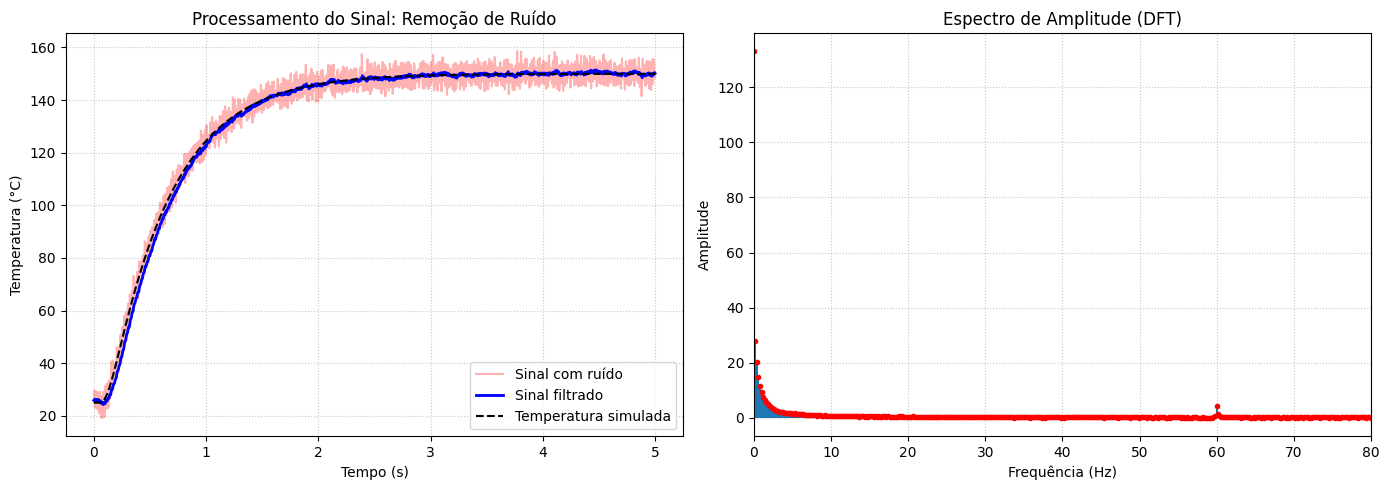


--- Avaliação da filtragem ---
Frequência analisada: 59.96 Hz
Amplitude antes da filtragem: 4.4725
Amplitude depois da filtragem: 0.4429
Redução da amplitude: 90.10%


In [26]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Parâmetros físicos do termopar

L_aco = 0.00030
L_mgo = 0.00120
L = L_aco + L_mgo

T_max = 5.0
Nx = 51

# Propriedades do aço inoxidável 316L
k_aco = 15.0
rho_aco = 7900.0
cp_aco = 500.0

# Propriedades do MgO compactado
k_mgo = 2.36
rho_mgo = 2000.0
cp_mgo = 1030.0

# 2. Malha espacial

x = np.linspace(0, L, Nx)
dx = x[1] - x[0]

k = np.where(x <= L_aco, k_aco, k_mgo)
rho = np.where(x <= L_aco, rho_aco, rho_mgo)
cp = np.where(x <= L_aco, cp_aco, cp_mgo)

k_face = 2 * k[:-1] * k[1:] / (k[:-1] + k[1:])

# Critério de estabilidade do FTCS
dt = 0.2 * np.min(rho * cp) * dx**2 / np.max(k)
Nt = int(T_max / dt) + 1

# 3. Frequência de amostragem do sinal

fs_desejada = 200.0

# Intervalo entre as amostras da simulação térmica
intervalo = max(1, round(1 / (fs_desejada * dt)))

fs = 1 / (intervalo * dt)

# 4. Simulação térmica pelo método FTCS

u = np.ones(Nx) * 25.0
u_novo = np.copy(u)

# Armazenamento das amostras da temperatura interna
historico_inox = [u[-1]]
vetor_tempo = [0.0]

for n in range(1, Nt):

    fluxo_direita = k_face[1:] * (u[2:] - u[1:-1])
    fluxo_esquerda = k_face[:-1] * (u[1:-1] - u[:-2])

    u_novo[1:-1] = u[1:-1] + (
        dt / (rho[1:-1] * cp[1:-1] * dx**2)
    ) * (fluxo_direita - fluxo_esquerda)

    # Superfície externa a 150 °C
    u_novo[0] = 150.0

    # Fluxo nulo na extremidade interna
    u_novo[-1] = u[-1] + (
        2 * dt * k_face[-1] * (u[-2] - u[-1]) /
        (rho[-1] * cp[-1] * dx**2)
    )

    u = np.copy(u_novo)

    # Amostragem da temperatura interna
    if n % intervalo == 0:
        historico_inox.append(u[-1])
        vetor_tempo.append(n * dt)

historico_inox = np.array(historico_inox)
vetor_tempo = np.array(vetor_tempo)

N_amostras = len(historico_inox)

print(f"Passo temporal térmico: {dt:.3e} s")
print(f"Frequência de amostragem: {fs:.2f} Hz")
print(f"Quantidade de amostras: {N_amostras}")

# 5. Adição de ruídos industriais

np.random.seed(42)

ruido_60Hz = 5.0 * np.sin(
    2 * np.pi * 60 * vetor_tempo
)

ruido_branco = np.random.normal(
    0, 1.5, N_amostras
)

sinal_medido = (
    historico_inox + ruido_60Hz + ruido_branco
)

# 6. Funções manuais da DFT e IDFT

def fourier_disc(s):
    N = len(s)
    X = np.zeros(N, dtype=np.complex128)
    n = np.arange(N)

    for k in range(N):
        X[k] = np.sum(
            s * np.exp(-2j * np.pi * k * n / N)
        )

    return X


def fourier_inv_disc(X):
    N = len(X)
    s = np.zeros(N, dtype=np.complex128)
    k = np.arange(N)

    for n in range(N):
        s[n] = np.sum(
            X * np.exp(2j * np.pi * k * n / N)
        ) / N

    return s.real


# 7. Aplicação da DFT ao sinal original

X_manual = fourier_disc(sinal_medido)

# 8. Preparação do sinal para a filtragem

# Extensão por reflexão para reduzir efeitos nas extremidades
sinal_estendido = np.pad(
    sinal_medido,
    (N_amostras, N_amostras),
    mode='reflect'
)

N_estendido = len(sinal_estendido)

# DFT do sinal estendido
X_estendido = fourier_disc(sinal_estendido)

# 9. Filtragem digital: filtro RC passa-baixas

f_corte = 5.0

X_filtrado = np.zeros(N_estendido, dtype=np.complex128)

for k in range(N_estendido):

    # Frequências positivas e negativas
    if k <= N_estendido // 2:
        freq = (k * fs) / N_estendido
    else:
        freq = ((k - N_estendido) * fs) / N_estendido

    # Função de transferência do filtro RC
    H_rc = 1 / (1 + 1j * (freq / f_corte))

    # Aplicação do filtro
    X_filtrado[k] = X_estendido[k] * H_rc

# 10. Reconstrução do sinal filtrado pela IDFT

sinal_estendido_filtrado = fourier_inv_disc(X_filtrado)

# Retirada das partes adicionadas por reflexão
sinal_recuperado = sinal_estendido_filtrado[
    N_amostras:2 * N_amostras
]

# 11. Espectro de amplitude do sinal medido

metade = N_amostras // 2

amplitudes = 2 * np.abs(
    X_manual[:metade]
) / N_amostras

amplitudes[0] = np.abs(X_manual[0]) / N_amostras

frequencias_metade = (
    np.arange(metade) * fs / N_amostras
)

# 12. Visualização dos resultados

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Domínio do tempo
ax1.plot(
    vetor_tempo, sinal_medido,
    color='red', alpha=0.3,
    label='Sinal com ruído'
)

ax1.plot(
    vetor_tempo, sinal_recuperado,
    color='blue', linewidth=2,
    label='Sinal filtrado'
)

ax1.plot(
    vetor_tempo, historico_inox,
    'k--', linewidth=1.5,
    label='Temperatura simulada'
)

ax1.set_title('Processamento do Sinal: Remoção de Ruído')
ax1.set_xlabel('Tempo (s)')
ax1.set_ylabel('Temperatura (°C)')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle=':', alpha=0.7)

# Domínio da frequência
ax2.stem(
    frequencias_metade,
    amplitudes,
    basefmt=" ",
    markerfmt="r."
)

ax2.set_xlim(0, 80)
ax2.set_title('Espectro de Amplitude (DFT)')
ax2.set_xlabel('Frequência (Hz)')
ax2.set_ylabel('Amplitude')
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# 13. Avaliação da redução do ruído de 60 Hz

# DFT do sinal após a filtragem
X_depois = fourier_disc(sinal_recuperado)

# Índice da frequência mais próxima de 60 Hz
indice_60 = round(60 * N_amostras / fs)

frequencia_60 = indice_60 * fs / N_amostras

# Amplitude antes e depois da filtragem
amplitude_antes = 2 * abs(X_manual[indice_60]) / N_amostras
amplitude_depois = 2 * abs(X_depois[indice_60]) / N_amostras

# Percentual de redução
reducao = (
    (amplitude_antes - amplitude_depois) /
    amplitude_antes
) * 100

print("\n--- Avaliação da filtragem ---")
print(f"Frequência analisada: {frequencia_60:.2f} Hz")
print(f"Amplitude antes da filtragem: {amplitude_antes:.4f}")
print(f"Amplitude depois da filtragem: {amplitude_depois:.4f}")
print(f"Redução da amplitude: {reducao:.2f}%")


### Conclusão do processamento digital do sinal

A etapa de processamento digital permitiu analisar a influência de ruídos sobre o sinal de temperatura simulado do termopar. Para isso, foram adicionados artificialmente uma interferência senoidal de 60 Hz e um ruído branco, representando possíveis perturbações presentes em ambientes industriais.

A aplicação da Transformada Discreta de Fourier (DFT) possibilitou analisar o sinal no domínio da frequência e identificar a componente associada à interferência de 60 Hz. Em seguida, foi utilizado um filtro RC passa-baixas, com frequência de corte de 5 Hz, para atenuar as componentes de frequência mais elevada.

Após a reconstrução do sinal pela Transformada Inversa de Fourier (IDFT), observou-se uma redução das oscilações, fazendo com que a temperatura filtrada acompanhasse mais suavemente a resposta térmica simulada.

Dessa forma, os resultados demonstram como o processamento digital pode contribuir para a redução de interferências em sinais de temperatura, melhorando sua apresentação e interpretação.

## REFERÊNCIAS BIBLIOGRÁFICAS

APERAM. **Stainless Steel 316L: Technical Data Sheet**. Disponível em: https://www.aperam.com/sites/default/files/documents/FT_316L_en_web.pdf. Acesso em: 2 nov. 2026.

ALUTAL. **Catálogo técnico: Termopares de isolação mineral**. Disponível em: https://www.alutal.com.br/wp-content/uploads/2023/06/catalogotecnicoalutal_194.pdf. Acesso em: 2 nov. 2026.

INTERNATIONAL ELECTROTECHNICAL COMMISSION (IEC). **IEC 61515:2016: Mineral insulated metal-sheathed thermocouple cables and thermocouples**. Genebra: IEC, 2016.

KME ITALY S.p.A. **Instruction Manual: Mineral Insulated Cables MICO and Their Terminations**. Disponível em: https://www.kme.com/fileadmin/DOWNLOADCENTER/COPPER%20DIVISON/6._Mineral_Insulated_Cables/Ueberarbeitet_MICO_ohne_Register_10.2022/KME_Italy_SpA_-_Instruction_Manual_-_Mineral_Insulated_Cables_MCO_and_their_terminations_rev_04.pdf. Acesso em: 2 nov. 2026.

NATIONAL INSTITUTE OF STANDARDS AND TECHNOLOGY (NIST). **Structural Ceramics Database: Magnesium Oxide (MgO)**. Disponível em: https://srdata.nist.gov/CeramicDataPortal/Scd/Z00181. Acesso em: 2 nov. 2026.

SMITH, Steven W. **The Scientist and Engineer’s Guide to Digital Signal Processing**. 2. ed. California Technical Publishing, 1999. Disponível em: https://www.analog.com/en/resources/technical-books/scientist_engineers_guide.html. Acesso em: 2 nov. 2026.

YOKOGAWA. **TI 6B0A1-01E: Mineral Insulated Thermocouples**. Disponível em: https://web-material3.yokogawa.com/TI06B00A01-01EN.pdf. Acesso em: 2 nov. 2026.

**MATERIAL DIDÁTICO DA DISCIPLINA.** Aulas de Matemática Computacional II: equação do calor, diferenças finitas, método FTCS, Transformada Discreta de Fourier e processamento de sinais. Material disponibilizado pelo docente.